# Equity analysis

Phase N. Are the gaps in air-quality monitoring concentrated in lower-income areas, and where would a new monitor do the most good? Each grid cell has a population, an income proxy, a distance to the nearest station (notebook 12) and a predicted PM2.5 (notebook 11). The statistics compare groups of *people*: income groups holding equal numbers of people, and the share of each group that lives in the monitoring desert.

Two things about what each result rests on. How many people of each income group live far from a station depends only on the station locations, the population and the income proxy, not on the PM2.5 model. The comparison of predicted pollution inside and outside the desert does depend on the model, whose predictions are compressed at high values and uncertain cell by cell, so it is checked against the uncertainty band and kept to rank-based statements where it can.

In [1]:
%load_ext autoreload
%autoreload 2

## Imports

In [2]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import yaml
from scipy.stats import spearmanr

import monitoring_deserts.features.deserts as deserts
import monitoring_deserts.features.equity as equity

## Configuration

The main desert threshold is the one drawn on the map of notebook 12; the others show how much the answer depends on it. The bootstrap resamples blocks of the map (`BOOT_BLOCK_DEG` degrees on a side), because neighbouring cells are strongly correlated and a bootstrap over single cells would make every result look far more certain than it is.

In [11]:
# Generic settings
with open("../configs/project_config.yaml") as f:
    gen_config = yaml.safe_load(f)

PROCESSED_DATA_DIR = Path(gen_config["data_dir"]["processed"]) # The data/processed/ should have no subdirs
CLEAN_DATA_DIR = Path(gen_config["data_dir"]["clean"])
EQUITY_DATA_DIR = CLEAN_DATA_DIR / "equity"
MAPS_DIR = Path(gen_config["output_dir"]["maps"]) / "equity"
PLOTS_DIR = Path(gen_config["output_dir"]["plots"]) / "equity"
for directory in (EQUITY_DATA_DIR, MAPS_DIR, PLOTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

CELL_SIZE = gen_config["grid_cell_size_deg"]

THRESHOLDS_KM = [25, 50, 100, 200] # desert = nearest station farther than this
MAIN_THRESHOLD_KM = 100            # the one used for the tables and the ranking
N_GROUPS = 5                       # income groups with equal numbers of people (quintiles)
BOOT_BLOCK_DEG = 3.0               # side of the map blocks resampled by the bootstrap
N_BOOT = 300
ZONE_DEG = 0.5                     # side of the candidate zones for new monitors (10 x 10 cells)
TOP_N = 10
RANDOM_STATE = 42

## Outline

1. ~~**Step 1 - Assemble the cell table.** Population, income proxies, distance to the nearest station and predicted PM2.5 (with its band) for every cell, and the sample the analysis uses.~~
2. ~~**Step 2 - Income groups and the desert.** Population-weighted quintiles of the Relative Wealth Index; for each, how many people live in the desert at each threshold, and the predicted pollution inside and outside the desert.~~
3. ~~**Step 3 - Is distance to a station related to income?** Spearman correlation across cells and a partial correlation controlling for population density and for night-time lights (urban against rural), each with a block-bootstrap interval.~~
4. ~~**Step 4 - Where would a new monitor do the most good?** Rank the desert zones by exposure (population times predicted PM2.5), and check how stable the ranking is under the prediction band.~~
5. ~~**Step 5 - Robustness.** A second income proxy (night-time lights per person), the gap between the poorest and richest groups at every threshold, and the pollution comparison at the lower and upper prediction bounds.~~
6. ~~**Step 6 - Save.**~~

## Step 1 - Assemble the cell table

The predicted PM2.5 of a cell is the mean over the 16 months of notebook 11, and the band is the mean of the monthly lower and upper bounds. The grid has no cell with a population of exactly zero: a cell either has a value or is empty (NaN). The empty cells cannot be told apart in this table into ocean, uninhabited land and land outside the countries whose population was downloaded, so they are left out and counted. The analysis uses the cells with a population and a prediction.

In [4]:
grid = gpd.read_parquet(PROCESSED_DATA_DIR / "grid.parquet")[["cell_id", "centroid_lon", "centroid_lat"]]
static = pd.read_parquet(CLEAN_DATA_DIR / "population" / "grid_features.parquet", columns=["cell_id", "population", "rwi", "rwi_distance_km", "viirs"])
status = pd.read_parquet(PROCESSED_DATA_DIR / "cell_monitoring_status.parquet", columns=["cell_id", "distance_to_station_km"])
predictions = (
    pd.read_parquet(PROCESSED_DATA_DIR / "grid_predictions.parquet", columns=["cell_id", "predicted_pm25", "pm25_lower", "pm25_upper"])
    .groupby("cell_id").mean().reset_index()
    .rename(columns={"predicted_pm25": "pm25", "pm25_lower": "pm25_low", "pm25_upper": "pm25_high"})
)

cells = grid
for table in (static, status, predictions):
    cells = cells.merge(table, on="cell_id", how="left", validate="one_to_one")

cells["area_km2"] = deserts.cell_area_km2(cells["centroid_lat"], CELL_SIZE)
cells["density"] = cells["population"] / cells["area_km2"]            # people per km2, the urban/rural stand-in
cells["viirs_per_person"] = cells["viirs"] / cells["population"]      # night-time light per person, the second income proxy

# Blocks of the map for the bootstrap
cells["block"] = np.floor(cells["centroid_lon"] / BOOT_BLOCK_DEG).astype(int) * 1000 + np.floor(cells["centroid_lat"] / BOOT_BLOCK_DEG).astype(int)

usable = cells["population"].gt(0) & cells["pm25"].notna() & cells["distance_to_station_km"].notna()
sample = cells[usable].reset_index(drop=True)
with_rwi = sample["rwi"].notna()

print(f"{len(cells):,} cells; {cells['population'].isna().sum():,} without population data are left out")
print(f"Analysis sample: {len(sample):,} cells holding {sample['population'].sum():,.0f} people")
print(f"  with an RWI value: {with_rwi.sum():,} cells ({sample.loc[with_rwi, 'population'].sum() / sample['population'].sum():.1%} of the people)")

434,940 cells; 279,850 without population data are left out
Analysis sample: 155,033 cells holding 1,800,289,024 people
  with an RWI value: 137,025 cells (99.7% of the people)


## Step 2 - Income groups and the desert

The Relative Wealth Index (RWI) is the primary income proxy, taken from the nearest RWI point (within 5 km, otherwise missing). The groups are population-weighted quintiles: the poorest group holds a fifth of the people in cells with an RWI, whichever number of cells that takes. Group 0 is the poorest and the highest group the richest.

For each threshold the table gives the share of each group's people who live in the desert. If the gaps were unrelated to income, every group would have about the same share.

In [5]:
rwi_sample = sample[with_rwi].reset_index(drop=True)
rwi_sample["income_group"], rwi_cutoffs = equity.weighted_quantile_groups(rwi_sample["rwi"], rwi_sample["population"], N_GROUPS)
print("RWI cut-offs between the groups:", np.round(rwi_cutoffs, 3))

share_by_threshold = pd.DataFrame({
    t: equity.group_status_table(
        rwi_sample["income_group"], rwi_sample["distance_to_station_km"] > t, rwi_sample["population"]
    )["share_in_desert"]
    for t in THRESHOLDS_KM
})
share_by_threshold.index = [f"{int(g)}" + (" (poorest)" if g == 0 else " (richest)" if g == N_GROUPS - 1 else "") for g in share_by_threshold.index]
share_by_threshold.columns = [f"> {t} km" for t in THRESHOLDS_KM]
print("Share of each income group's people living in the desert")
share_by_threshold.style.format("{:.1%}")

RWI cut-offs between the groups: [-0.323 -0.05   0.261  0.714]
Share of each income group's people living in the desert


,> 25 km,> 50 km,> 100 km,> 200 km
0 (poorest),91.7%,71.4%,35.7%,12.9%
1,88.6%,65.7%,29.1%,8.5%
2,84.8%,60.0%,24.9%,6.9%
3,74.5%,52.2%,22.7%,8.5%
4 (richest),42.8%,32.5%,19.8%,9.3%


In [7]:
main_table = equity.group_status_table(
    rwi_sample["income_group"], rwi_sample["distance_to_station_km"] > MAIN_THRESHOLD_KM,
    rwi_sample["population"], values=rwi_sample["pm25"],
)
main_table["share_of_all_people_in_desert"] = main_table["desert_population"] / main_table["desert_population"].sum()
print(f"Desert = more than {MAIN_THRESHOLD_KM} km from a station; PM2.5 is the population-weighted mean prediction (ug/m3)")
main_table.style.format({"population": "{:,.0f}", "desert_population": "{:,.0f}", "share_in_desert": "{:.1%}",
                         "share_of_all_people_in_desert": "{:.1%}", "mean_value_monitored": "{:.1f}", "mean_value_desert": "{:.1f}"})

Desert = more than 100 km from a station; PM2.5 is the population-weighted mean prediction (ug/m3)


,population,desert_population,share_in_desert,mean_value_monitored,mean_value_desert,share_of_all_people_in_desert
group,,,,,,
0,"359,903,745","128,605,476",35.7%,37.4,38.5,27.1%
1,"359,621,713","104,637,959",29.1%,37.7,38.5,22.0%
2,"358,277,148","89,085,146",24.9%,38.2,38.1,18.8%
3,"359,031,467","81,530,294",22.7%,38.4,38.8,17.2%
4,"358,540,570","71,167,666",19.8%,39.6,39.8,15.0%


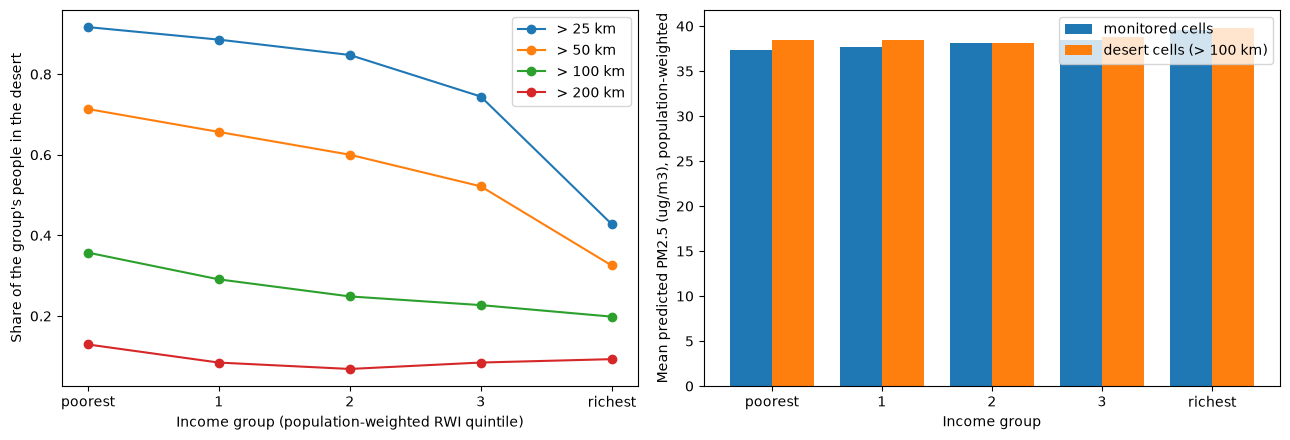

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for t in THRESHOLDS_KM:
    axes[0].plot(range(N_GROUPS), share_by_threshold[f"> {t} km"], marker="o", label=f"> {t} km")
axes[0].set_xticks(range(N_GROUPS))
axes[0].set_xticklabels(["poorest"] + [str(g) for g in range(1, N_GROUPS - 1)] + ["richest"])
axes[0].set_xlabel("Income group (population-weighted RWI quintile)")
axes[0].set_ylabel("Share of the group's people in the desert")
axes[0].legend()

width = 0.38
positions = np.arange(N_GROUPS)
axes[1].bar(positions - width / 2, main_table["mean_value_monitored"], width, label="monitored cells")
axes[1].bar(positions + width / 2, main_table["mean_value_desert"], width, label=f"desert cells (> {MAIN_THRESHOLD_KM} km)")
axes[1].set_xticks(positions)
axes[1].set_xticklabels(["poorest"] + [str(g) for g in range(1, N_GROUPS - 1)] + ["richest"])
axes[1].set_xlabel("Income group")
axes[1].set_ylabel("Mean predicted PM2.5 (ug/m3), population-weighted")
axes[1].legend()
fig.tight_layout()
fig.savefig(PLOTS_DIR / "income_group_desert.png", dpi=150)
plt.show()

Reading notes: the left panel is the central equity picture: a line sloping down from the poorest to the richest group means the poor are more often far from a monitor. It does not use the PM2.5 model at all. The right panel does use it, so differences of a few ug/m3 are within the prediction uncertainty of notebook 11; Step 5 repeats the comparison at the lower and upper bounds of the band. A group with very few people on one side (almost nobody monitored, or almost nobody in the desert) has a noisy mean on that side.

## Step 3 - Is distance to a station related to income?

A rank (Spearman) correlation between a cell's distance to the nearest station and its RWI, across cells: negative means that richer cells are nearer to stations. Population density can drive both (dense cities have more stations and a different wealth index than sparse countryside), so the partial correlation removes the linear rank effect of the density, and of the night-time light (another urban-against-rural indicator) in a second version. A control cannot remove a nonlinear or unmeasured confounder.

Textbook p-values assume independent cells, which these are not, so the uncertainty is the interval from resampling blocks of the map.

In [9]:
distance = rwi_sample["distance_to_station_km"].to_numpy()
rwi = rwi_sample["rwi"].to_numpy()
density = rwi_sample["density"].to_numpy()
radiance = rwi_sample["viirs"].to_numpy()
blocks = rwi_sample["block"].to_numpy()

statistics = {
    "Spearman, distance vs RWI": lambda i: spearmanr(distance[i], rwi[i])[0],
    "partial, controlling density": lambda i: equity.partial_spearman(distance[i], rwi[i], density[i]),
    "partial, controlling density and night light": lambda i: equity.partial_spearman(distance[i], rwi[i], np.column_stack([density[i], radiance[i]])),
}
correlation_table = pd.DataFrame({
    name: equity.block_bootstrap(statistic, blocks, n_boot=N_BOOT, random_state=RANDOM_STATE)
    for name, statistic in statistics.items()
}).T[["estimate", "lower", "upper", "n_blocks"]]
print(f"95% intervals from {N_BOOT} resamples of {correlation_table['n_blocks'].iloc[0]} map blocks of {BOOT_BLOCK_DEG} degrees")
correlation_table.style.format({"estimate": "{:.3f}", "lower": "{:.3f}", "upper": "{:.3f}", "n_blocks": "{:.0f}"})

95% intervals from 300 resamples of 75.0 map blocks of 3.0 degrees


,estimate,lower,upper,n_blocks
"Spearman, distance vs RWI",-0.247,-0.301,-0.183,75
"partial, controlling density",-0.078,-0.122,-0.025,75
"partial, controlling density and night light",0.010,-0.028,0.056,75


Reading notes: an interval that excludes zero says the association is not an artefact of which blocks happened to be in the sample; it does not say the association is causal, nor that income is the cause. If the partial values are much closer to zero than the plain one, density explains most of the apparent link. The size matters as much as the sign: a correlation of -0.05 with a tight interval is a real but very weak relation.

## Step 4 - Where would a new monitor do the most good?

Exposure is the predicted PM2.5 times the population: it counts how many people-micrograms a cell holds, so it is high where many people live in polluted air. Cells are grouped into candidate zones of `ZONE_DEG` degrees (10 x 10 cells), because a ranking of single 5 km cells would be a list of neighbours of the same few cities. Only desert cells enter: the question is where the missing monitors are.

Exposure is dominated by population, so the top zones are the densely populated parts of the desert. The prediction uncertainty matters less for the ranking than for the levels, which is checked by recomputing the ranking at the lower and upper bounds of the band.

In [12]:
desert_cells = sample[sample["distance_to_station_km"] > MAIN_THRESHOLD_KM].copy()
for name, column in (("point", "pm25"), ("low", "pm25_low"), ("high", "pm25_high")):
    desert_cells[f"exposure_{name}"] = desert_cells[column] * desert_cells["population"]

desert_cells["zone"] = (
    np.floor(desert_cells["centroid_lon"] / ZONE_DEG).astype(int).astype(str) + "_" +
    np.floor(desert_cells["centroid_lat"] / ZONE_DEG).astype(int).astype(str)
)
desert_cells["lon_x_pop"] = desert_cells["centroid_lon"] * desert_cells["population"]
desert_cells["lat_x_pop"] = desert_cells["centroid_lat"] * desert_cells["population"]
desert_cells["dist_x_pop"] = desert_cells["distance_to_station_km"] * desert_cells["population"]

zones = desert_cells.groupby("zone").agg(
    n_cells=("cell_id", "size"), population=("population", "sum"),
    exposure=("exposure_point", "sum"), exposure_low=("exposure_low", "sum"), exposure_high=("exposure_high", "sum"),
    lon_x_pop=("lon_x_pop", "sum"), lat_x_pop=("lat_x_pop", "sum"), dist_x_pop=("dist_x_pop", "sum"),
).reset_index()
zones["lon"] = zones["lon_x_pop"] / zones["population"]
zones["lat"] = zones["lat_x_pop"] / zones["population"]
zones["mean_pm25"] = zones["exposure"] / zones["population"]
zones["mean_distance_km"] = zones["dist_x_pop"] / zones["population"]
zones = zones.drop(columns=["lon_x_pop", "lat_x_pop", "dist_x_pop"]).sort_values("exposure", ascending=False).reset_index(drop=True)
zones["rank"] = np.arange(1, len(zones) + 1)

print(f"{len(zones):,} desert zones holding {zones['population'].sum():,.0f} people")
zones.head(TOP_N).style.format({"population": "{:,.0f}", "exposure": "{:.3g}", "exposure_low": "{:.3g}", "exposure_high": "{:.3g}",
                                "lon": "{:.2f}", "lat": "{:.2f}", "mean_pm25": "{:.1f}", "mean_distance_km": "{:.0f}"})

1,058 desert zones holding 478,786,368 people


,zone,n_cells,population,exposure,exposure_low,exposure_high,lon,lat,mean_pm25,mean_distance_km,rank
0,134_49,90,"11,088,364",5.39e+08,2.63e+08,1.14e+09,67.10,24.88,48.6,441,1
1,146_62,67,"4,845,413",2.55e+08,1.25e+08,5.4e+08,73.12,31.37,52.7,118,2
2,143_68,100,"4,563,166",2.16e+08,1.05e+08,4.57e+08,71.77,34.19,47.3,282,3
3,142_60,100,"3,870,623",2.11e+08,1.03e+08,4.45e+08,71.38,30.18,54.4,241,4
4,146_67,100,"3,900,654",1.87e+08,9.1e+07,3.95e+08,73.16,33.66,47.8,160,5
5,183_44,60,"5,431,122",1.79e+08,8.64e+07,3.8e+08,91.84,22.34,32.9,173,6
6,133_49,35,"3,573,347",1.65e+08,8.05e+07,3.5e+08,66.97,24.90,46.2,453,7
7,176_48,94,"3,998,854",1.62e+08,7.88e+07,3.43e+08,88.27,24.23,40.5,123,8
8,178_51,100,"3,901,892",1.53e+08,7.45e+07,3.25e+08,89.28,25.76,39.3,140,9
9,144_68,100,"3,181,427",1.48e+08,7.21e+07,3.13e+08,72.23,34.22,46.5,239,10


In [13]:
# How stable is the ranking under the prediction band?
rank_stability = {}
for name in ("exposure_low", "exposure_high"):
    top_point = set(zones.nsmallest(TOP_N, "rank")["zone"])
    top_other = set(zones.nlargest(TOP_N, name)["zone"])
    rank_stability[name] = {
        "spearman_with_point_ranking": spearmanr(zones["exposure"], zones[name])[0],
        f"top_{TOP_N}_in_common": len(top_point & top_other),
    }
pd.DataFrame(rank_stability).T

,spearman_with_point_ranking,top_10_in_common
exposure_low,0.999992,10.0
exposure_high,0.999996,10.0


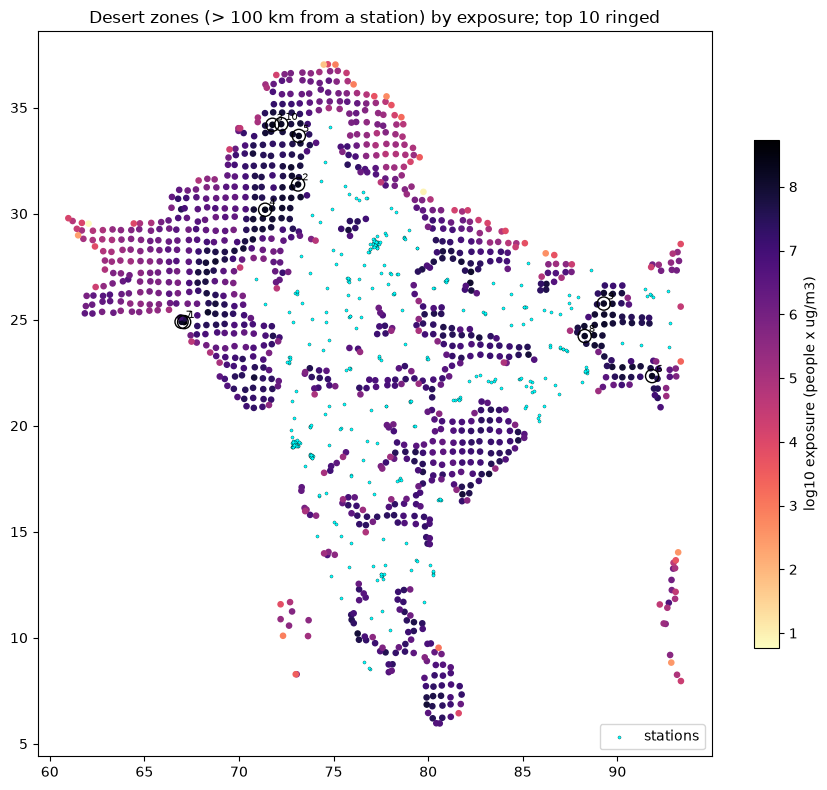

In [14]:
stations = pd.read_parquet(PROCESSED_DATA_DIR / "master_station_df.parquet", columns=["station_id", "longitude", "latitude"]).drop_duplicates("station_id")

fig, ax = plt.subplots(figsize=(9, 8))
points = ax.scatter(zones["lon"], zones["lat"], c=np.log10(zones["exposure"]), s=14, cmap="magma_r")
ax.scatter(zones.head(TOP_N)["lon"], zones.head(TOP_N)["lat"], s=90, facecolors="none", edgecolors="black")
for _, zone in zones.head(TOP_N).iterrows():
    ax.annotate(str(int(zone["rank"])), (zone["lon"], zone["lat"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.scatter(stations["longitude"], stations["latitude"], s=5, color="cyan", edgecolor="black", linewidth=0.2, label="stations")
ax.set_title(f"Desert zones (> {MAIN_THRESHOLD_KM} km from a station) by exposure; top {TOP_N} ringed")
ax.legend(loc="lower right")
fig.colorbar(points, ax=ax, shrink=0.7, label="log10 exposure (people x ug/m3)")
fig.tight_layout()
fig.savefig(MAPS_DIR / "desert_zones_by_exposure.png", dpi=150)
plt.show()

Reading notes: the ranked table is the list of zones where a new monitor would cover the most people-weighted pollution, given the model. It is a ranking, not a measurement: zones near the top rest on predictions far from any station, where the model is least checked (the cross-validation tests transfer over about 90-260 km). A high overlap of the top zones under the lower and upper bounds says the choice of zones does not hinge on the level of the predictions. It does not say the predictions are right in those zones.

## Step 5 - Robustness

Two further checks on the central result. First, the same gap between the poorest and the richest group (share of people in the desert, poorest minus richest, so positive means the poor are more often far from a station) is computed at every threshold and for a second income proxy, night-time light per person (higher is richer), which is available for every populated cell but confounded with density, so it is a cross-check and not an equal. Each comes with a block-bootstrap interval, in which the income groups are re-cut in every resample. Second, the pollution comparison of Step 2 is repeated at the lower and upper bounds of the prediction band.

In [15]:
def desert_share_gap(income, population, distance_km, threshold_km):
    """Share of the poorest group's people in the desert minus the same for the richest group."""
    def statistic(i):
        groups, _ = equity.weighted_quantile_groups(income[i], population[i], N_GROUPS)
        in_desert = distance_km[i] > threshold_km
        shares = []
        for group in (0, N_GROUPS - 1):
            members = groups == group
            shares.append(population[i][members & in_desert].sum() / population[i][members].sum())
        return shares[0] - shares[1]
    return statistic


proxies = {
    "RWI": rwi_sample,
    "night light per person": sample[sample["viirs_per_person"].notna()].reset_index(drop=True),
}
proxy_column = {"RWI": "rwi", "night light per person": "viirs_per_person"}

gap_rows = []
for proxy_name, proxy_sample in proxies.items():
    income = proxy_sample[proxy_column[proxy_name]].to_numpy()
    population_values = proxy_sample["population"].to_numpy()
    distance_values = proxy_sample["distance_to_station_km"].to_numpy()
    for t in THRESHOLDS_KM:
        result = equity.block_bootstrap(
            desert_share_gap(income, population_values, distance_values, t), proxy_sample["block"].to_numpy(),
            n_boot=N_BOOT, random_state=RANDOM_STATE,
        )
        gap_rows.append({"proxy": proxy_name, "threshold_km": t, **{k: result[k] for k in ("estimate", "lower", "upper")}})
gap_table = pd.DataFrame(gap_rows).set_index(["proxy", "threshold_km"])
print("Poorest minus richest group: share of people living in the desert (percentage points), 95% block-bootstrap interval")
(gap_table * 100).style.format("{:.1f}")

Poorest minus richest group: share of people living in the desert (percentage points), 95% block-bootstrap interval


In [16]:
# The pollution comparison at the lower and upper bounds of the prediction band
band_rows = {}
for label, column in (("lower bound", "pm25_low"), ("point prediction", "pm25"), ("upper bound", "pm25_high")):
    table = equity.group_status_table(
        rwi_sample["income_group"], rwi_sample["distance_to_station_km"] > MAIN_THRESHOLD_KM, rwi_sample["population"], values=rwi_sample[column],
    )
    gap = table["mean_value_desert"] - table["mean_value_monitored"]
    band_rows[label] = {"poorest group: desert minus monitored": gap.loc[0], "richest group: desert minus monitored": gap.loc[N_GROUPS - 1]}
print(f"Mean predicted PM2.5 in the desert minus outside it (ug/m3), desert = more than {MAIN_THRESHOLD_KM} km")
pd.DataFrame(band_rows).T.style.format("{:.2f}")

Mean predicted PM2.5 in the desert minus outside it (ug/m3), desert = more than 100 km


,poorest group: desert minus monitored,richest group: desert minus monitored
lower bound,0.56,0.11
point prediction,1.13,0.22
upper bound,2.35,0.46


Reading notes: a gap whose interval stays on one side of zero at every threshold and for both proxies is a pattern of the data; one that changes sign with the threshold or the proxy is not a finding. The band sensitivity is a check, not a correction: if the sign of a pollution difference flips between the lower and the upper bound, the model cannot tell the direction of that difference. Everything here describes the study period (March 2025 to June 2026) and the grid cells with population data.

## Step 6 - Save

In [17]:
zones.to_parquet(EQUITY_DATA_DIR / "desert_zones_ranked.parquet")


def records(table):
    """A DataFrame as a list of plain Python records (NaN becomes null)."""
    return json.loads(table.reset_index().to_json(orient="records"))


metadata = {
    "income_proxy": "Relative Wealth Index, within 5 km of an RWI point; population-weighted quintiles (0 = poorest)",
    "second_income_proxy": "night-time light per person (VIIRS / population), a cross-check only",
    "thresholds_km": [int(t) for t in THRESHOLDS_KM],
    "main_threshold_km": int(MAIN_THRESHOLD_KM),
    "bootstrap": {"block_deg": float(BOOT_BLOCK_DEG), "n_boot": int(N_BOOT), "level": 0.95, "random_state": int(RANDOM_STATE)},
    "zone_deg": float(ZONE_DEG),
    "sample": {
        "n_cells_total": int(len(cells)),
        "n_cells_without_population": int(cells["population"].isna().sum()),
        "n_cells_in_sample": int(len(sample)),
        "population_in_sample": float(sample["population"].sum()),
        "n_cells_with_rwi": int(len(rwi_sample)),
        "population_with_rwi": float(rwi_sample["population"].sum()),
    },
    "rwi_cutoffs": [float(c) for c in rwi_cutoffs],
    "share_in_desert_by_group_and_threshold": records(share_by_threshold),
    "main_threshold_table": records(main_table),
    "correlations": records(correlation_table),
    "poorest_minus_richest_desert_share": records(gap_table),
    "pm25_gap_by_band_bound": records(pd.DataFrame(band_rows).T),
    "ranking_stability": records(pd.DataFrame(rank_stability).T),
    "n_desert_zones": int(len(zones)),
    "files": {"zones": str(EQUITY_DATA_DIR / "desert_zones_ranked.parquet")},
    "note": "Associations, not causes; income proxies are proxies; predicted PM2.5 carries the uncertainty of notebook 11.",
}
with open("../configs/equity_metadata.yaml", "w") as f:
    yaml.safe_dump(metadata, f, sort_keys=False)